# Simulate and reconstruct 3D GRE with Wave-CAIPI

[`01_build`](01_build.ipynb) wrote four files: Wave and no-Wave, each fully sampled and
R = 2 x 2 CAIPI. This notebook builds the Wave point-spread function (PSF) from the nominal
trajectory, checks it on a matched model, then simulates the files with MRzero and reconstructs
them, fully sampled and accelerated.

The reconstruction is a small, explicit forward model written for this example. It is not
SeqCraft API.

In [1]:
import os
import sys

SIM_THREADS = 4
for _var in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'RAYON_NUM_THREADS',
             'OPENBLAS_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[_var] = str(SIM_THREADS)

import contextlib
import io
import time
import warnings

warnings.filterwarnings('ignore', message='IProgress not found')   # tqdm, on import

from pathlib import Path

import matplotlib.pyplot as plt
import MRzeroCore as mr0
import numpy as np
import pypulseq as pp
import torch

import seqcraft as sc

sys.path.insert(0, str(Path('..').resolve()))
import phantom as ph            # noqa: E402 -- the shared BrainWeb preparation, one directory up

torch.set_num_threads(SIM_THREADS)
plt.rcParams['figure.dpi'] = 72

## Load the written sequences

`01` saved the protocol, the sampling tables and `WaveReadout.k_per_m()` next to the files.

In [2]:
SEQ_DIR = Path('seq')
nominal = np.load(SEQ_DIR / 'gre_wave_caipi_3d_nominal.npz')
NX, NY, NZ = (int(v) for v in nominal['matrix'])
OS = int(nominal['oversampling'])
N = NX * OS
ECHO = int(nominal['echo_sample'])
FOV_M = nominal['fov_mm'] / 1e3
TABLES = {'full': [tuple(int(v) for v in r) for r in nominal['full']],
          'caipi': [tuple(int(v) for v in r) for r in nominal['caipi']]}
FILES = {(name, size): SEQ_DIR / f'gre_wave_caipi_3d_{name}_{size}.seq'
         for name in ('wave', 'plain') for size in ('full', 'caipi')}
print(f'{NX} x {NY} x {NZ}, {OS}x readout oversampling ({N} samples), echo sample {ECHO}')
for key, file in FILES.items():
    print(f'  {key[0]:5s} {key[1]:5s} {file}')

32 x 32 x 8, 4x readout oversampling (128 samples), echo sample 64
  wave  full  seq/gre_wave_caipi_3d_wave_full.seq
  wave  caipi seq/gre_wave_caipi_3d_wave_caipi.seq
  plain full  seq/gre_wave_caipi_3d_plain_full.seq
  plain caipi seq/gre_wave_caipi_3d_plain_caipi.seq


## Build the nominal Wave PSF

The Wave's displacement is `dk(t_n) = k(t_n) - k_line`: the trajectory at each ADC sample time
minus the Cartesian line's encoding target. In the reconstruction's hybrid space (x in k-space,
y and z in image space) the Wave multiplies every sample by the PSF

```text
PSF(t_n, y, z) = exp(-i 2 pi (dky(t_n) y + dkz(t_n) z))
```

There is one nominal trajectory: the emitted gradients integrated exactly to the actual ADC
sample times, from each excitation's RF centre. Three independent implementations reach it here:

- `WaveReadout.k_per_m()`, the module's own report, saved by `01`;
- the written file, read back and measured with `sc.sequence_kspace`;
- MRzero's own reader of the written file.

On a scanner, a measured correction would be added to this nominal trajectory before the PSF is
built: nominal `k_adc` from the `.seq`, plus the measured `delta_k_adc`, gives the calibrated
`k_adc`. That calibration belongs to the reconstruction, not to SeqCraft.

In [3]:
def read_back(path):
    # The file's nominal trajectory at its ADC samples.
    seq = pp.Sequence()
    seq.read(str(path))
    return sc.sequence_kspace(seq)['k_adc']


def mrzero_k(path):
    return mr0.Sequence.import_file(str(path)).get_kspace()[:, :3].numpy().T.astype(float)


def encoding_target(table):
    # (3, lines): what the phase encoding puts on x, y, z for each (line, partition).
    return np.stack([np.zeros(len(table)),
                     nominal['encoded_y'][[line for line, _ in table]],
                     nominal['encoded_z'][[part for _, part in table]]])


def displacement(k, table=TABLES['full']):
    # (3, N) Wave displacement, and its largest spread over the repetitions.
    per_rep = k.reshape(3, len(table), N) - encoding_target(table)[:, :, None]
    mean = per_rep.mean(axis=1)
    return mean, float(np.abs(per_rep - mean[:, None]).max())


k_file = {'wave': read_back(FILES[('wave', 'full')]), 'plain': read_back(FILES[('plain', 'full')])}
k_mrzero = {'wave': mrzero_k(FILES[('wave', 'full')]), 'plain': mrzero_k(FILES[('plain', 'full')])}

routes = {"WaveReadout.k_per_m()": nominal['wave_k_per_m']}
for name, k in (('file, sc.sequence_kspace', k_file['wave']),
                ("file, MRzero's reader", k_mrzero['wave'])):
    routes[name], spread = displacement(k)
    print(f'{name:26s} spread over the {len(TABLES["full"])} repetitions {spread:.1e} 1/m')
print('largest difference from WaveReadout.k_per_m() on any axis (1/m):')
for name, dk in routes.items():
    print(f'  {name:26s} {np.abs(dk - routes["WaveReadout.k_per_m()"]).max():.1e}')
reach = np.abs(routes['WaveReadout.k_per_m()'][1:]).max()
print(f'(the Wave reaches |dk| {reach:.1f} 1/m on y and z; '
      f'one k-space step in y is {1 / FOV_M[1]:.1f} 1/m)')

file, sc.sequence_kspace   spread over the 256 repetitions 1.2e-04 1/m
file, MRzero's reader      spread over the 256 repetitions 1.3e-04 1/m
largest difference from WaveReadout.k_per_m() on any axis (1/m):
  WaveReadout.k_per_m()      0.0e+00
  file, sc.sequence_kspace   3.3e-05
  file, MRzero's reader      3.1e-05
(the Wave reaches |dk| 17.2 1/m on y and z; one k-space step in y is 5.0 1/m)


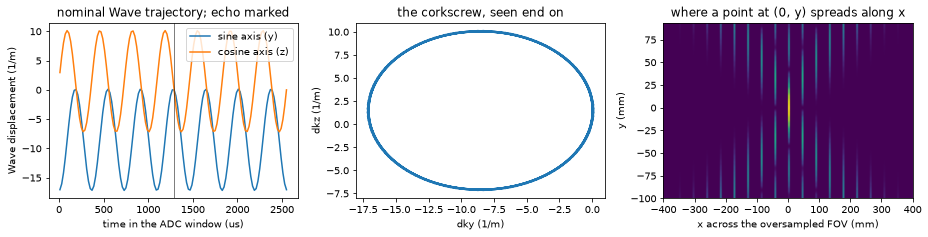

In [4]:
y_pos = (np.arange(NY) - NY // 2) * FOV_M[1] / NY
z_pos = (np.arange(NZ) - NZ // 2) * FOV_M[2] / NZ
x_pos = (np.arange(NX) - NX // 2) * FOV_M[0] / NX


def wave_psf(dk):
    # (N, NY, NZ): exp(-i 2 pi (dky * y + dkz * z)) on the reconstruction grid.
    return np.exp(-2j * np.pi * (dk[1][:, None, None] * y_pos[None, :, None]
                                 + dk[2][:, None, None] * z_pos[None, None, :]))


def fftc(x, axes):
    return np.fft.fftshift(np.fft.fftn(np.fft.ifftshift(x, axes=axes), axes=axes, norm='ortho'),
                           axes=axes)


def ifftc(x, axes):
    return np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(x, axes=axes), axes=axes, norm='ortho'),
                           axes=axes)


DK = routes['WaveReadout.k_per_m()']
crop = slice(N // 2 - NX // 2, N // 2 + NX // 2)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
t_us = (np.arange(N) + 0.5) * float(nominal['dwell_s']) * 1e6
axes[0].plot(t_us, DK[1], label='sine axis (y)')
axes[0].plot(t_us, DK[2], label='cosine axis (z)')
axes[0].axvline(t_us[ECHO], color='k', lw=0.5)
axes[0].set(xlabel='time in the ADC window (us)', ylabel='Wave displacement (1/m)',
            title='nominal Wave trajectory; echo marked')
axes[0].legend()
axes[1].plot(DK[1], DK[2])
axes[1].set(xlabel='dky (1/m)', ylabel='dkz (1/m)', title='the corkscrew, seen end on')
spread = np.abs(ifftc(wave_psf(DK), (0,)))
half_fov_mm = OS * FOV_M[0] / 2e-3
axes[2].imshow(spread[:, :, NZ // 2].T, aspect='auto', origin='lower',
               extent=[-half_fov_mm, half_fov_mm, y_pos[0] * 1e3, y_pos[-1] * 1e3])
axes[2].set(xlabel='x across the oversampled FOV (mm)', ylabel='y (mm)',
            title='where a point at (0, y) spreads along x')
plt.tight_layout()

**Sign.** If a simulator's data are `sum rho exp(sigma i 2 pi k . r)` for either sign `sigma`, the
inverse FFT over the encoded y and z leaves `exp(-i 2 pi dk . r)` on the reconstruction grid: the
`sigma` that mirrors the image also mirrors the grid. The PSF's sign is therefore fixed by the
reconstruction's FFT convention, not by the simulator.

## Matched-model check of the trajectory and PSF

Here the object sits on the reconstruction grid, as point voxels, so the encoding the signal goes
through and the model the reconstruction inverts are the same operator. The signal is computed as
`sum rho(r) exp(-i 2 pi k(t_n) . r)` along MRzero's reading of the written file. With the right
nominal trajectory and PSF, the Wave reconstruction returns the object to numerical precision.

no Wave                                  relative error 8.8e-06
Wave, PSF from WaveReadout.k_per_m()     relative error 1.0e-05
Wave, PSF from the written file          relative error 9.1e-06
Wave, no PSF                             relative error 8.1e-01


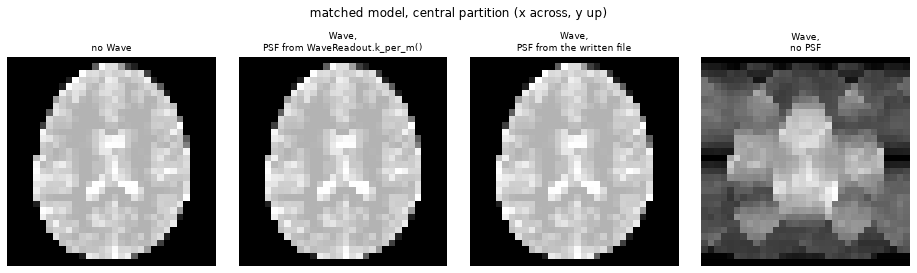

In [5]:
def on_grid(n_coils):
    # BrainWeb resampled to the reconstruction grid, with point voxels in y and z.
    volume = ph.slab_3d(matrix=(NX, NY, NZ), z_extent_mm=float(nominal['fov_mm'][2]),
                        n_coils=n_coils)
    step_mm = FOV_M * 1e3 / np.array([NX, NY, NZ])
    affine = np.eye(4, dtype=np.float32)
    affine[:3, :3] = np.diag(step_mm)
    affine[:3, 3] = -np.array([NX // 2, NY // 2, NZ // 2]) * step_mm
    volume.affine = torch.tensor(affine)
    data = volume.build(voxel_shape='point')

    # x keeps MRzero's usual cut-off at the voxel grid's Nyquist, so the readout spoiler still
    # dephases.  y and z have none: the Wave carries k beyond the grid's Nyquist there.
    def x_only(trajectory, nyquist):
        return torch.sigmoid((nyquist[0] - trajectory[:, 0].abs() + 0.5) * 100)

    data.dephasing_func = x_only
    return data


def dft(k, positions, weights, chunk=2048):
    # sum_v w_v exp(-i 2 pi k(n) . r_v) at every sample: the encoding and nothing else.
    out = np.empty(k.shape[1], complex)
    for start in range(0, k.shape[1], chunk):
        out[start:start + chunk] = np.exp(
            -2j * np.pi * (k[:, start:start + chunk].T @ positions.T)) @ weights
    return out


def cube(signal, table):
    # Place (lines * N, ...) samples into an (N, NY, NZ, ...) k-space cube.
    rows = signal.reshape(len(table), N, *signal.shape[1:])
    out = np.zeros((N, NY, NZ, *signal.shape[1:]), complex)
    for r, (line, part) in enumerate(table):
        out[:, line, part] = rows[r]
    return out


def direct(signal, table, dk=None):
    # Fully sampled reconstruction: y/z inverse FFT, undo the Wave PSF, x inverse FFT, crop.
    hybrid = ifftc(cube(signal, table), (1, 2))
    if dk is not None:
        psf = np.conj(wave_psf(dk))
        hybrid = hybrid * (psf if hybrid.ndim == 3 else psf[..., None])
    return ifftc(hybrid, (0,))[crop]


def relative_error(image, truth):
    # ||a - b|| / ||b|| after one complex scale (the FFT normalisation).
    a, b = image.reshape(-1), truth.reshape(-1)
    return float(np.linalg.norm(np.vdot(a, b) / np.vdot(a, a) * a - b) / np.linalg.norm(b))


grid_object = on_grid(n_coils=0)
positions = grid_object.voxel_pos.numpy().astype(float)
density = grid_object.PD.numpy().astype(complex)
index =np.round((positions - np.array([x_pos[0], y_pos[0], z_pos[0]]))
                 / (FOV_M / np.array([NX, NY, NZ]))).astype(int)
truth = np.zeros((NX, NY, NZ), complex)
truth[index[:, 0], index[:, 1], index[:, 2]] = density

matched = {name: dft(k_mrzero[name], positions, density) for name in ('plain', 'wave')}
images = {
    'no Wave': direct(matched['plain'], TABLES['full']),
    'Wave, PSF from WaveReadout.k_per_m()': direct(matched['wave'], TABLES['full'],
                                                   routes['WaveReadout.k_per_m()']),
    'Wave, PSF from the written file': direct(matched['wave'], TABLES['full'],
                                              routes['file, sc.sequence_kspace']),
    'Wave, no PSF': direct(matched['wave'], TABLES['full']),
}
for name, image in images.items():
    print(f'{name:40s} relative error {relative_error(image, truth):.1e}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, image) in zip(axes, images.items()):
    ax.imshow(np.abs(image[:, :, NZ // 2]).T, cmap='gray', origin='lower')
    ax.set_title(name.replace(', ', ',\n'), fontsize=9)
    ax.axis('off')
plt.suptitle('matched model, central partition (x across, y up)', y=1.04)
plt.tight_layout()

Both nominal routes give the same image as the no-Wave acquisition, and the same as each other.
Without the PSF, every voxel stays spread along x.

**Sensitivity experiment.** How much does a trajectory error cost? The cell below deliberately
shifts the gradient waveform by 5 us, half a gradient raster, as an uncorrected gradient delay
would. This is a perturbation of the nominal trajectory, not another nominal trajectory
estimator, and no reconstruction in this notebook uses it.

The shifted trajectory is integrated exactly, by `calculate_kspacePP(trajectory_delay=-5e-6)`:
the integration behind `sc.sequence_kspace`, called directly because `sc.sequence_kspace`
describes only the nominal sequence and takes no delay. The pinned `calculate_kspace()`, whose
own error is about this size, is not used to make the shift
([`pypulseq_dependency.md`](../../docs/pypulseq_dependency.md)).

In [6]:
# Sensitivity experiment: the gradients deliberately 5 us late, integrated exactly.
# A perturbation of the nominal trajectory; no reconstruction below uses it.
late_seq = pp.Sequence()
late_seq.read(str(FILES[('wave', 'full')]))
late, _ = displacement(np.asarray(late_seq.calculate_kspacePP(trajectory_delay=-5e-6)[0]))
error = relative_error(direct(matched['wave'], TABLES['full'], late), truth)
print(f'Wave displacement error up to {np.abs(late - DK)[1:].max():.2f} 1/m on y and z; '
      f'relative error {error:.2f}')

Wave displacement error up to 0.89 1/m on y and z; relative error 0.19


## Fully sampled reconstruction

MRzero now simulates the written files with the phantom's relaxation and B0 map, RF spoiling and
an eight-element receive ring, on the same reconstruction-grid phantom. `01` plays 200 dummies
first. A spoiled-GRE transient weights k-space line by line, and that weighting does not commute
with the Wave PSF, so the acquisition has to be close to steady state when the lines start.

In [7]:
def simulate(path, obj, *, states=200, state_mag=1e-4, emitted=1e-4, latent=1e-5):
    seq = mr0.Sequence.import_file(str(path))
    with contextlib.redirect_stdout(io.StringIO()):         # MRzero's own timing printout
        graph = mr0.compute_graph(seq, obj, max_state_count=states, min_state_mag=state_mag)
    signal = mr0.execute_graph(graph, seq, obj, min_emitted_signal=emitted,
                               min_latent_signal=latent, print_progress=False)
    return np.asarray(signal.detach().cpu().numpy())


phantom = on_grid(n_coils=8)
signals = {}
for key, file in FILES.items():
    started = time.time()
    signals[key] = simulate(file, phantom)
    print(f'{key[0]:5s} {key[1]:5s} {signals[key].shape}  {time.time() - started:.0f} s')

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001343167 s
Compute Graph


Computing Graph: 0.17143221 s
Analyze Graph
Analyzing Graph: 0.004295458 s
Converting Rust -> Python: 0.07202313 s
<<<< Rust <<<<


wave  full  (32768, 8)  47 s


>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001235625 s
Compute Graph
Computing Graph: 0.07059092 s
Analyze Graph
Analyzing Graph: 0.001699459 s
Converting Rust -> Python: 0.02963304 s
<<<< Rust <<<<


wave  caipi (8192, 8)  23 s


>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001298875 s
Compute Graph
Computing Graph: 0.10626738 s
Analyze Graph
Analyzing Graph: 0.003707459 s
Converting Rust -> Python: 0.059443623 s
<<<< Rust <<<<


plain full  (32768, 8)  27 s
>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.000620083 s
Compute Graph


Computing Graph: 0.03469204 s
Analyze Graph
Analyzing Graph: 0.001508334 s
Converting Rust -> Python: 0.026057 s
<<<< Rust <<<<


plain caipi (8192, 8)  8 s


no Wave                                  NRMSE against no Wave 0.0000
Wave, PSF from WaveReadout.k_per_m()     NRMSE against no Wave 0.0259
Wave, PSF from the written file          NRMSE against no Wave 0.0259
Wave, no PSF                             NRMSE against no Wave 0.4355


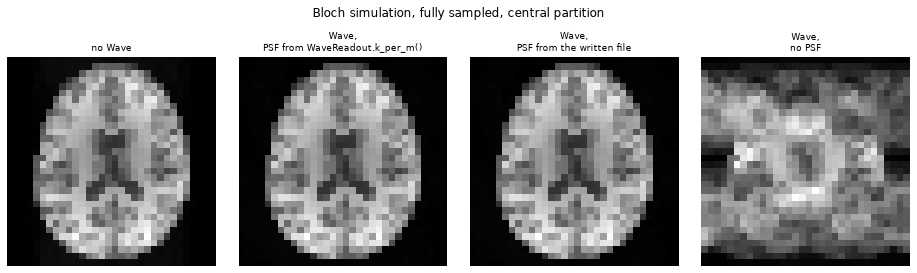

In [8]:
def rss(image):
    return np.sqrt(np.sum(np.abs(image) ** 2, axis=-1))


def nrmse(image, ref, mask=None):
    # Magnitude NRMSE inside the object, after one real scale.
    mask = ref > 0.1 * ref.max() if mask is None else mask
    a = np.abs(image) * np.sum(np.abs(image) * ref * mask) / np.sum(np.abs(image) ** 2 * mask)
    return float(np.sqrt(np.sum(((a - ref) * mask) ** 2) / np.sum((ref * mask) ** 2)))


reference = rss(direct(signals[('plain', 'full')], TABLES['full']))
full = {
    'no Wave': reference,
    'Wave, PSF from WaveReadout.k_per_m()': rss(direct(signals[('wave', 'full')], TABLES['full'],
                                                       routes['WaveReadout.k_per_m()'])),
    'Wave, PSF from the written file': rss(direct(signals[('wave', 'full')], TABLES['full'],
                                                  routes['file, sc.sequence_kspace'])),
    'Wave, no PSF': rss(direct(signals[('wave', 'full')], TABLES['full'])),
}
for name, image in full.items():
    print(f'{name:40s} NRMSE against no Wave {nrmse(image, reference):.4f}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (name, image) in zip(axes, full.items()):
    ax.imshow(image[:, :, NZ // 2].T, cmap='gray', origin='lower')
    ax.set_title(name.replace(', ', ',\n'), fontsize=9)
    ax.axis('off')
plt.suptitle('Bloch simulation, fully sampled, central partition', y=1.04)
plt.tight_layout()

The two nominal PSFs give the same image again, and the Wave reconstruction is close to the no-Wave
one. It is not exact, as it was above. The encoding alone was exact, so the remaining NRMSE of
about 0.026 is not the trajectory or the PSF. It is an unresolved discrepancy between the simulated
magnetisation and the reconstruction's model, and its source is not identified. Repeated runs on
the same files differ in the fourth decimal place.

## R = 2 x 2 Wave-CAIPI reconstruction

CG-SENSE on the hybrid-space forward model:

```text
image -> coil sensitivity -> zero-pad to the oversampled FOV -> FFT along x
      -> x Wave PSF (Wave files only) -> FFT along y, z -> the sampled lines
```

The coil maps come from the fully sampled no-Wave acquisition, standing in for a calibration
scan, and the same maps serve every reconstruction. What Wave-CAIPI improves is noise
amplification, so that is measured by pseudo-replica: complex noise is added to the k-space data,
and the voxel-wise standard deviation of the R = 4 reconstruction is divided by `sqrt(R)` times
that of the fully sampled one under the same encoding.

In [9]:
coil_images = direct(signals[('plain', 'full')], TABLES['full'])
coil_rss = rss(coil_images)
support = coil_rss > 0.08 * coil_rss.max()
maps = np.where(support[..., None], coil_images / np.maximum(coil_rss, 1e-12)[..., None], 0)
COILS = maps.shape[-1]


class Encoding:
    # The forward model above, for one table, with or without a Wave PSF.

    def __init__(self, table, psf):
        self.lines = np.array([line for line, _ in table])
        self.parts = np.array([part for _, part in table])
        self.psf = psf

    def forward(self, u):
        padded = np.zeros((N, NY, NZ, COILS), complex)
        padded[crop] = maps * u[..., None]
        hybrid = fftc(padded, (0,))
        if self.psf is not None:
            hybrid = hybrid * self.psf[..., None]
        return fftc(hybrid, (1, 2))[:, self.lines, self.parts, :]

    def adjoint(self, data):
        k = np.zeros((N, NY, NZ, COILS), complex)
        np.add.at(k, (slice(None), self.lines, self.parts), data)
        hybrid = ifftc(k, (1, 2))
        if self.psf is not None:
            hybrid = hybrid * np.conj(self.psf)[..., None]
        return np.sum(np.conj(maps) * ifftc(hybrid, (0,))[crop], axis=-1)


def cg_sense(encoding, data, iterations=30):
    b = encoding.adjoint(data)
    x, r = np.zeros_like(b), b.copy()
    p, rr = r.copy(), np.vdot(r, r)
    for _ in range(iterations):
        if abs(rr) < 1e-20 * abs(np.vdot(b, b)):          # converged exactly
            break
        ap = encoding.adjoint(encoding.forward(p)) * support
        alpha = rr / np.vdot(p, ap)
        x, r = x + alpha * p, r - alpha * ap
        rr, rr_old = np.vdot(r, r), rr
        p = r + (rr / rr_old) * p
    return x * support


psf = wave_psf(DK)
encodings = {(name, size): Encoding(TABLES[size], psf if name == 'wave' else None)
             for name in ('wave', 'plain') for size in ('full', 'caipi')}
data = {key: signals[key].reshape(len(TABLES[key[1]]), N, COILS).transpose(1, 0, 2)
        for key in encodings}
clean = {key: cg_sense(encodings[key], data[key]) for key in encodings}
for key, image in clean.items():
    print(f'{key[0]:5s} {key[1]:5s} NRMSE against the same encoding fully sampled '
          f'{nrmse(image, np.abs(clean[(key[0], "full")])):.3f}')

wave  full  NRMSE against the same encoding fully sampled 0.000
wave  caipi NRMSE against the same encoding fully sampled 0.035
plain full  NRMSE against the same encoding fully sampled 0.000
plain caipi NRMSE against the same encoding fully sampled 0.056


plain g-factor at R = 4: mean 2.08, 95th percentile 3.73, max 6.63
wave  g-factor at R = 4: mean 1.12, 95th percentile 1.57, max 2.61


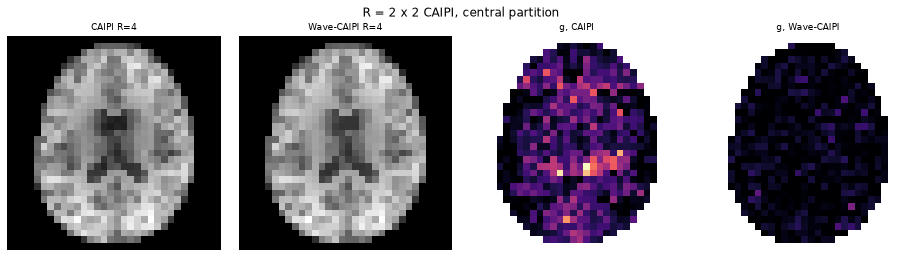

In [10]:
REPLICAS = 12
sigma = 0.03 * np.abs(data[('plain', 'full')]).mean()
rng = np.random.default_rng(1)
noise_std = {}
for key, encoding in encodings.items():
    replicas = []
    for _ in range(REPLICAS):
        noise = sigma * (rng.standard_normal(data[key].shape)
                         + 1j * rng.standard_normal(data[key].shape)) / np.sqrt(2)
        replicas.append(cg_sense(encoding, data[key] + noise) - clean[key])
    noise_std[key] = np.std(np.stack(replicas), axis=0)
R = len(TABLES['full']) / len(TABLES['caipi'])
with np.errstate(invalid='ignore', divide='ignore'):        # zero outside the support
    g = {name: np.where(support, noise_std[(name, 'caipi')]
                        / (noise_std[(name, 'full')] * np.sqrt(R)), np.nan)
         for name in ('plain', 'wave')}
for name, gmap in g.items():
    values = gmap[support]
    print(f'{name:5s} g-factor at R = {R:.0f}: mean {values.mean():.2f}, '
          f'95th percentile {np.percentile(values, 95):.2f}, max {values.max():.2f}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
panels = [('CAIPI R=4', np.abs(clean[('plain', 'caipi')])),
          ('Wave-CAIPI R=4', np.abs(clean[('wave', 'caipi')])),
          ('g, CAIPI', g['plain']), ('g, Wave-CAIPI', g['wave'])]
top = max(np.percentile(g['plain'][support], 99), np.percentile(g['wave'][support], 99))
for ax, (name, image) in zip(axes, panels):
    shown = image[:, :, NZ // 2].T
    kwargs = dict(vmin=1.0, vmax=top, cmap='magma') if name.startswith('g') else dict(cmap='gray')
    ax.imshow(shown, origin='lower', **kwargs)
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.suptitle('R = 2 x 2 CAIPI, central partition')
plt.tight_layout()

This is a 32 x 32 x 8 simulation-sized protocol (3.5 mT/m, 7 cycles, a 2.56 ms window) with an
eight-element synthetic ring. It shows the emitted Wave lowering noise amplification here, not
what it does at clinical matrices or with a real array.

## Optional: a phantom finer than the reconstruction grid

Everything above used an object on the reconstruction grid. A real object has structure finer
than the image grid. The PSF is applied at voxel centres, which is the standard Wave-CAIPI model,
but within one 6.25 mm voxel the Wave phase varies by up to `max|dky| * dy`, about 0.1 cycle here.
The model ignores that intravoxel phase, so content finer than the grid does not reconstruct
exactly. That residual is a **spatial-model discretisation error**, not a trajectory error.

To see it on its own, the matched-model check is repeated with the encoding alone, on BrainWeb
twice as fine in each direction, and compared with the same phantom on the reconstruction grid.

Wave with the nominal PSF against no Wave, encoding only (magnitude NRMSE):
  object on the reconstruction grid     5.1e-06
  object twice as fine                  7.7e-02


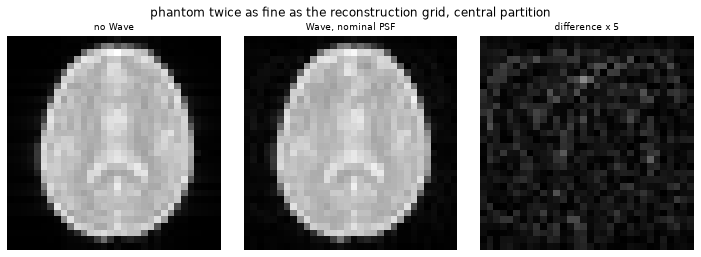

In [11]:
fine_object = ph.built_3d(matrix=(2 * NX, 2 * NY, 2 * NZ),
                          z_extent_mm=float(nominal['fov_mm'][2]), n_coils=0)
fine_positions = fine_object.voxel_pos.numpy().astype(float)
fine_density = fine_object.PD.numpy().astype(complex)
fine = {name: dft(k_mrzero[name], fine_positions, fine_density) for name in ('plain', 'wave')}
fine_images = {'no Wave': direct(fine['plain'], TABLES['full']),
               'Wave, nominal PSF': direct(fine['wave'], TABLES['full'], DK)}
print('Wave with the nominal PSF against no Wave, encoding only (magnitude NRMSE):')
print(f'  object on the reconstruction grid     '
      f'{nrmse(images["Wave, PSF from the written file"], np.abs(images["no Wave"])):.1e}')
print(f'  object twice as fine                  '
      f'{nrmse(fine_images["Wave, nominal PSF"], np.abs(fine_images["no Wave"])):.1e}')

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
pair = [np.abs(fine_images[name][:, :, NZ // 2]) for name in ('no Wave', 'Wave, nominal PSF')]
scale = np.sum(pair[0] * pair[1]) / np.sum(pair[1] ** 2)
for ax, (name, image) in zip(axes, [('no Wave', pair[0]), ('Wave, nominal PSF', scale * pair[1]),
                                     ('difference x 5', 5 * np.abs(pair[0] - scale * pair[1]))]):
    ax.imshow(image.T, cmap='gray', origin='lower', vmin=0, vmax=pair[0].max())
    ax.set_title(name, fontsize=9)
    ax.axis('off')
plt.suptitle('phantom twice as fine as the reconstruction grid, central partition')
plt.tight_layout()

In [12]:
assert relative_error(images['Wave, PSF from WaveReadout.k_per_m()'], truth) < 1e-4
assert relative_error(images['Wave, PSF from the written file'], truth) < 1e-4
assert relative_error(images['Wave, no PSF'], truth) > 0.5
assert (nrmse(full['Wave, no PSF'], reference)
        > 10 * nrmse(full['Wave, PSF from the written file'], reference))
assert g['wave'][support].mean() < g['plain'][support].mean()
assert nrmse(fine_images['Wave, nominal PSF'], np.abs(fine_images['no Wave'])) > 100 * nrmse(
    images['Wave, PSF from the written file'], np.abs(images['no Wave']))